# MNIST + EMNIST 공식 분할 기반 16클래스 데이터셋 재구성

- MNIST 공식 Training 60,000 / Test 10,000 유지
- EMNIST 대문자 A~F 각각 Training 6,000 / Test 1,000
- EMNIST Test: 공식 Test 우선, 부족하면 미사용 공식 Training 원본으로 보충
- EMNIST Training 부족분: Training에 남은 원본으로만 이동 증강
- 원본·증강과 출처를 기록하며 Test 누수 방지

**주의:** 교수님 프로젝트 가이드의 초기 학습용 Training/Validation 기준과 팀이 요청한 Training/Test 기준의 차이는 팀 내 확인이 필요합니다.

In [1]:
import numpy as np
from torchvision.datasets import MNIST, EMNIST
from scipy.ndimage import shift

SEED = 42
rng = np.random.default_rng(SEED)

mnist_train = MNIST(root="./data", train=True, download=True)
mnist_test = MNIST(root="./data", train=False, download=True)
emnist_train = EMNIST(root="./data", split="byclass", train=True, download=True)
emnist_test = EMNIST(root="./data", split="byclass", train=False, download=True)

print("원본 데이터셋 준비 완료")

원본 데이터셋 준비 완료


In [2]:
print("MNIST 공식 구분")
for i in range(10):
    tr = int((mnist_train.targets == i).sum())
    te = int((mnist_test.targets == i).sum())
    print(f"{i}: Train {tr}, Test {te}")

print("\nEMNIST A~F 공식 구분")
for i, letter in enumerate("ABCDEF", start=10):
    tr = int((emnist_train.targets == i).sum())
    te = int((emnist_test.targets == i).sum())
    print(f"{letter}: Train {tr}, Test {te}, Test 부족 {max(0, 1000 - te)}")

MNIST 공식 구분
0: Train 5923, Test 980
1: Train 6742, Test 1135
2: Train 5958, Test 1032
3: Train 6131, Test 1010
4: Train 5842, Test 982
5: Train 5421, Test 892
6: Train 5918, Test 958
7: Train 6265, Test 1028
8: Train 5851, Test 974
9: Train 5949, Test 1009

EMNIST A~F 공식 구분
A: Train 6407, Test 1062, Test 부족 0
B: Train 3878, Test 648, Test 부족 352
C: Train 10094, Test 1739, Test 부족 0
D: Train 4562, Test 779, Test 부족 221
E: Train 4934, Test 851, Test 부족 149
F: Train 9182, Test 1440, Test 부족 0


In [3]:
X_train_parts = [mnist_train.data.numpy().astype(np.uint8)]
y_train_parts = [mnist_train.targets.numpy().astype(np.uint8)]
X_test_parts = [mnist_test.data.numpy().astype(np.uint8)]
y_test_parts = [mnist_test.targets.numpy().astype(np.uint8)]
train_is_augmented_parts = [np.zeros(len(mnist_train), dtype=np.bool_)]
train_source_split_parts = [np.zeros(len(mnist_train), dtype=np.uint8)]
test_source_split_parts = [np.ones(len(mnist_test), dtype=np.uint8)]
train_source_index_parts = [np.arange(len(mnist_train), dtype=np.int32)]
test_source_index_parts = [np.arange(len(mnist_test), dtype=np.int32)]

emnist_log = []
for label, letter in enumerate("ABCDEF", start=10):
    train_indices = np.flatnonzero(emnist_train.targets.numpy() == label)
    test_indices = np.flatnonzero(emnist_test.targets.numpy() == label)
    n_official_test = min(1000, len(test_indices))
    picked_test = rng.choice(test_indices, size=n_official_test, replace=False)
    n_borrowed = 1000 - n_official_test
    borrowed = rng.choice(train_indices, size=n_borrowed, replace=False)
    available_train = np.setdiff1d(train_indices, borrowed, assume_unique=False)
    n_original_train = min(6000, len(available_train))
    picked_train = rng.choice(available_train, size=n_original_train, replace=False)
    n_aug = 6000 - n_original_train

    train_images = emnist_train.data[picked_train].numpy().transpose(0, 2, 1).copy()
    test_images_official = emnist_test.data[picked_test].numpy().transpose(0, 2, 1).copy()
    test_images_borrowed = emnist_train.data[borrowed].numpy().transpose(0, 2, 1).copy()
    test_images = np.concatenate([test_images_official, test_images_borrowed])

    augmented_images = []
    augmented_parent = []
    if n_aug:
        parent_positions = rng.choice(n_original_train, size=n_aug, replace=True)
        for pos in parent_positions:
            dx = int(rng.choice([-2, -1, 1, 2]))
            dy = int(rng.choice([-2, -1, 1, 2]))
            moved = shift(train_images[pos], shift=(dy, dx), order=0, mode="constant", cval=0)
            augmented_images.append(moved.astype(np.uint8))
            augmented_parent.append(int(picked_train[pos]))
        augmented_images = np.stack(augmented_images)
        train_images_final = np.concatenate([train_images, augmented_images])
    else:
        train_images_final = train_images

    X_train_parts.append(train_images_final)
    y_train_parts.append(np.full(6000, label, dtype=np.uint8))
    train_is_augmented_parts.append(np.r_[np.zeros(n_original_train, dtype=np.bool_), np.ones(n_aug, dtype=np.bool_)])
    train_source_split_parts.append(np.zeros(6000, dtype=np.uint8))
    train_source_index_parts.append(np.r_[picked_train, np.array(augmented_parent, dtype=np.int32)])
    X_test_parts.append(test_images)
    y_test_parts.append(np.full(1000, label, dtype=np.uint8))
    test_source_split_parts.append(np.r_[np.ones(n_official_test, dtype=np.uint8), np.zeros(n_borrowed, dtype=np.uint8)])
    test_source_index_parts.append(np.r_[picked_test, borrowed].astype(np.int32))
    assert len(train_images_final) == 6000 and len(test_images) == 1000
    assert not np.intersect1d(np.r_[picked_train, np.asarray(augmented_parent, dtype=np.int32)], borrowed).size
    emnist_log.append((letter, len(train_indices), len(test_indices), n_original_train, n_aug, n_official_test, n_borrowed))

X_train_final = np.concatenate(X_train_parts)
y_train_final = np.concatenate(y_train_parts)
X_test_final = np.concatenate(X_test_parts)
y_test_final = np.concatenate(y_test_parts)
train_is_augmented = np.concatenate(train_is_augmented_parts)
train_source_split = np.concatenate(train_source_split_parts)
test_source_split = np.concatenate(test_source_split_parts)
train_source_index = np.concatenate(train_source_index_parts)
test_source_index = np.concatenate(test_source_index_parts)

print("문자 | 공식 Train | 공식 Test | Train 원본 | Train 증강 | Test 공식 | Test Train차용")
for item in emnist_log:
    print("{:>2} | {:>10} | {:>9} | {:>10} | {:>10} | {:>9} | {:>13}".format(*item))

문자 | 공식 Train | 공식 Test | Train 원본 | Train 증강 | Test 공식 | Test Train차용
 A |       6407 |      1062 |       6000 |          0 |      1000 |             0
 B |       3878 |       648 |       3526 |       2474 |       648 |           352
 C |      10094 |      1739 |       6000 |          0 |      1000 |             0
 D |       4562 |       779 |       4341 |       1659 |       779 |           221
 E |       4934 |       851 |       4785 |       1215 |       851 |           149
 F |       9182 |      1440 |       6000 |          0 |      1000 |             0


In [4]:
assert X_train_final.shape == (96000, 28, 28)
assert X_test_final.shape == (16000, 28, 28)
assert np.array_equal(np.bincount(y_train_final, minlength=16)[:10], np.bincount(mnist_train.targets.numpy(), minlength=10))
assert np.array_equal(np.bincount(y_test_final, minlength=16)[:10], np.bincount(mnist_test.targets.numpy(), minlength=10))
assert np.all(np.bincount(y_train_final, minlength=16)[10:] == 6000)
assert np.all(np.bincount(y_test_final, minlength=16)[10:] == 1000)
assert X_train_final.dtype == np.uint8 and X_test_final.dtype == np.uint8

for label in range(16):
    train_ids = set(zip(train_source_split[y_train_final == label].tolist(), train_source_index[y_train_final == label].tolist()))
    test_ids = set(zip(test_source_split[y_test_final == label].tolist(), test_source_index[y_test_final == label].tolist()))
    assert train_ids.isdisjoint(test_ids), f"원본 누수: label={label}"

assert not np.any(train_is_augmented[0:60000])
assert int(train_is_augmented.sum()) == sum(row[4] for row in emnist_log)
print("Training:", X_train_final.shape, "Test:", X_test_final.shape)
print("증강 이미지 수:", int(train_is_augmented.sum()))
print("Test 중 공식 Training에서 차용한 EMNIST 원본 수:", sum(row[6] for row in emnist_log))
print("공식 분할 유지 및 데이터 누수 검증 완료")

Training: (96000, 28, 28) Test: (16000, 28, 28)
증강 이미지 수: 5348
Test 중 공식 Training에서 차용한 EMNIST 원본 수: 722
공식 분할 유지 및 데이터 누수 검증 완료


In [5]:
filename = "MNIST_EMNIST_official_split_112000.npz"
np.savez_compressed(
    filename,
    X_train=X_train_final, y_train=y_train_final,
    X_test=X_test_final, y_test=y_test_final,
    train_is_augmented=train_is_augmented,
    train_source_split=train_source_split,
    test_source_split=test_source_split,
    train_source_index=train_source_index,
    test_source_index=test_source_index,
    emnist_class_log=np.array(emnist_log, dtype="U16"),
    seed=np.array(SEED),
)
with np.load(filename) as check:
    assert check["X_train"].shape == (96000, 28, 28)
    assert check["X_test"].shape == (16000, 28, 28)
print("파일 저장 및 재검증 완료:", filename)

파일 저장 및 재검증 완료: MNIST_EMNIST_official_split_112000.npz


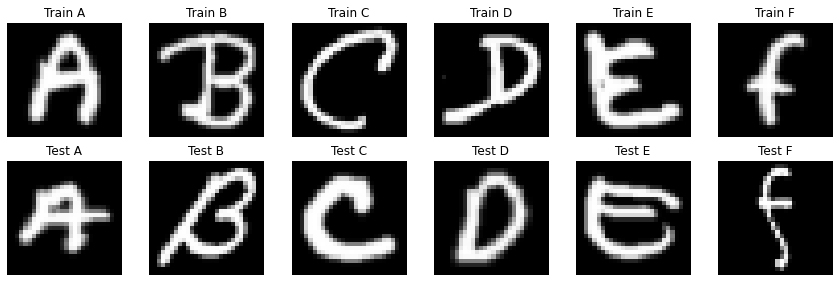

In [6]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for i, letter in enumerate("ABCDEF"):
    label = i + 10
    tr = np.flatnonzero((y_train_final == label) & (~train_is_augmented))[0]
    te = np.flatnonzero(y_test_final == label)[0]
    axes[0, i].imshow(X_train_final[tr], cmap="gray")
    axes[0, i].set_title(f"Train {letter}")
    axes[1, i].imshow(X_test_final[te], cmap="gray")
    axes[1, i].set_title(f"Test {letter}")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
plt.tight_layout()
plt.show()

In [7]:
import numpy as np

with np.load("MNIST_EMNIST_official_split_112000.npz") as data:
    print("저장된 항목:", data.files)

    for key in data.files:
        print(key, data[key].shape)

저장된 항목: ['X_train', 'y_train', 'X_test', 'y_test', 'train_is_augmented', 'train_source_split', 'test_source_split', 'train_source_index', 'test_source_index', 'emnist_class_log', 'seed']
X_train (96000, 28, 28)
y_train (96000,)
X_test (16000, 28, 28)
y_test (16000,)
train_is_augmented (96000,)
train_source_split (96000,)
test_source_split (16000,)
train_source_index (96000,)
test_source_index (16000,)
emnist_class_log (6, 7)
seed ()


In [8]:
import numpy as np

with np.load("MNIST_EMNIST_official_split_112000.npz") as data:
    train_labels = data["y_train"]
    test_labels = data["y_test"]
    train_splits = data["train_source_split"]
    test_splits = data["test_source_split"]
    train_indices = data["train_source_index"]
    test_indices = data["test_source_index"]

    train_sources = set(zip(
        train_labels.tolist(),
        train_splits.tolist(),
        train_indices.tolist()
    ))

    test_sources = set(zip(
        test_labels.tolist(),
        test_splits.tolist(),
        test_indices.tolist()
    ))

    overlap = train_sources & test_sources

    print("Training/Test 원본 중복:", len(overlap), "개")

    for i, letter in enumerate("ABCDEF"):
        label = i + 10
        print(
            f"{letter}:",
            "Training", np.sum(train_labels == label),
            "/ Test", np.sum(test_labels == label)
        )

Training/Test 원본 중복: 0 개
A: Training 6000 / Test 1000
B: Training 6000 / Test 1000
C: Training 6000 / Test 1000
D: Training 6000 / Test 1000
E: Training 6000 / Test 1000
F: Training 6000 / Test 1000


In [9]:
import numpy as np

with np.load("MNIST_EMNIST_official_split_112000.npz") as data:
    labels = data["y_test"]
    splits = data["test_source_split"]
    augmented = data["train_is_augmented"]
    train_labels = data["y_train"]

    print("EMNIST 클래스별 Test 구성")

    for i, letter in enumerate("ABCDEF"):
        label = i + 10
        mask = labels == label

        values, counts = np.unique(splits[mask], return_counts=True)
        source_counts = dict(zip(values.tolist(), counts.tolist()))

        print(
            f"{letter}: Test 출처 {source_counts}, "
            f"Training 증강 {np.sum(augmented & (train_labels == label))}개"
        )

EMNIST 클래스별 Test 구성
A: Test 출처 {1: 1000}, Training 증강 0개
B: Test 출처 {0: 352, 1: 648}, Training 증강 2474개
C: Test 출처 {1: 1000}, Training 증강 0개
D: Test 출처 {0: 221, 1: 779}, Training 증강 1659개
E: Test 출처 {0: 149, 1: 851}, Training 증강 1215개
F: Test 출처 {1: 1000}, Training 증강 0개
